# UWPR Contaminant Peak Analysis in NIST20 Data

Two-stage analysis:
1. **Stage 1 (Mass match)**: Find NIST20 peaks whose m/z matches a known UWPR contaminant within tolerance
2. **Stage 2 (Formula feasibility)**: Among mass-matched peaks, check if the contaminant formula could be a real fragment of the parent molecule (all element counts ≤ parent formula → plausibly real peak)

Peaks that match by mass but are **formula-infeasible** (contaminant formula has more of some element than the parent) are strong contaminant candidates.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
from tqdm.auto import tqdm

tqdm.pandas()

## 1. Load UWPR / MaConDa contaminant lists

In [2]:
DATA_DIR = Path("../../data/umpr")

# --- MaConDa (has formula + mz + ion_mode + type) ---
maconda = pd.read_csv(
    DATA_DIR / "UWPR_CommonMassSpecContaminants(MaConDa).csv",
    skiprows=3,
    dtype=str,
    encoding="latin-1",
)
maconda.columns = maconda.columns.str.strip()
maconda["mz"] = pd.to_numeric(maconda["mz"], errors="coerce")
maconda["exact_adduct_mass"] = pd.to_numeric(maconda["exact_adduct_mass"], errors="coerce")
maconda = maconda.dropna(subset=["mz"])
maconda["ion_mode"] = maconda["ion_mode"].str.strip()
print(f"MaConDa entries: {len(maconda)}, ion modes: {maconda['ion_mode'].value_counts().to_dict()}")
maconda.head(3)

MaConDa entries: 564, ion modes: {'POS': 545, 'NEG': 19}


In [3]:
# --- UWPR Positive file (Keller et al. 2008) ---
uwpr_pos_raw = pd.read_csv(
    DATA_DIR / "UWPR_CommonMassSpecContaminants(Positive).csv",
    skiprows=7,
    header=None,
    dtype=str,
    encoding="latin-1",
)
uwpr_pos = uwpr_pos_raw[[0, 1, 2, 3, 4]].copy()
uwpr_pos.columns = ["mz", "ion_type", "formula", "compound", "origin"]
uwpr_pos["mz"] = pd.to_numeric(uwpr_pos["mz"], errors="coerce")
uwpr_pos = uwpr_pos.dropna(subset=["mz"])
uwpr_pos["ion_mode"] = "POS"
print(f"UWPR Positive entries: {len(uwpr_pos)}")
uwpr_pos.head(3)

UWPR Positive entries: 822


,mz,ion_type,formula,compound,origin,ion_mode
1,33.033491,[M+H]+,CH3OH,Methanol,"Acetonitrile, solvent",POS
2,42.033825,[M+H]+,CH3CN,ACN,"Acetonitrile, solvent",POS
3,59.060374,[M+NH4]+,CH3CN,ACN,"Acetonitrile, solvent",POS


In [4]:
# --- UWPR Negative file ---
uwpr_neg_raw = pd.read_csv(
    DATA_DIR / "UWPR_CommonMassSpecContaminants(Negative).csv",
    skiprows=7,
    header=None,
    dtype=str,
    encoding="latin-1",
)
uwpr_neg = uwpr_neg_raw[[0, 1, 2, 3, 4]].copy()
uwpr_neg.columns = ["mz", "ion_type", "formula", "compound", "origin"]
uwpr_neg["mz"] = pd.to_numeric(uwpr_neg["mz"], errors="coerce")
uwpr_neg = uwpr_neg.dropna(subset=["mz"])
uwpr_neg["ion_mode"] = "NEG"
print(f"UWPR Negative entries: {len(uwpr_neg)}")
uwpr_neg.head(3)

UWPR Negative entries: 28


,mz,ion_type,formula,compound,origin,ion_mode
2,26.00362,f-,CN,CN-,Fragment from acetonitrile,NEG
3,44.99820,[M-H]-,HCOOH,(HCOO)-,"Formic acid, FA (anion), Formate",NEG
4,59.01385,[M-H]-,CH3COOH,(CH3CO2)-,"Acetic Acid, Ac (anion), Acetate",NEG


In [5]:
MZ_MAX = 1500.0  # consistent with spec_utils.MZ_MAX

# Build unified contaminant tables keyed by ion_mode
# MaConDa as primary (has formula info); UWPR Keller list fills in extra m/z values
maconda_pos = maconda[maconda["ion_mode"] == "POS"][
    ["mz", "formula", "name", "type_of_contaminant", "ion_form"]
].copy()
maconda_pos.columns = ["mz", "formula", "compound", "type", "ion_form"]
maconda_pos["source"] = "MaConDa"

maconda_neg = maconda[maconda["ion_mode"] == "NEG"][
    ["mz", "formula", "name", "type_of_contaminant", "ion_form"]
].copy()
maconda_neg.columns = ["mz", "formula", "compound", "type", "ion_form"]
maconda_neg["source"] = "MaConDa"

# UWPR Keller pos
uwpr_pos_slim = uwpr_pos[["mz", "formula", "compound", "ion_type"]].copy()
uwpr_pos_slim["type"] = "unknown"
uwpr_pos_slim["ion_form"] = uwpr_pos_slim["ion_type"]
uwpr_pos_slim["source"] = "UWPR_Keller"
uwpr_pos_slim = uwpr_pos_slim.drop(columns=["ion_type"])

# Merge, deduplicate, and drop entries above MZ_MAX
cont_pos = (
    pd.concat([maconda_pos, uwpr_pos_slim], ignore_index=True)
    .drop_duplicates(subset=["mz"])
    .query("mz <= @MZ_MAX")
    .reset_index(drop=True)
)
# UWPR Keller neg
uwpr_neg_slim = uwpr_neg[["mz", "formula", "compound", "ion_type"]].copy()
uwpr_neg_slim["type"] = "unknown"
uwpr_neg_slim["ion_form"] = uwpr_neg_slim["ion_type"]
uwpr_neg_slim["source"] = "UWPR_Keller"
uwpr_neg_slim = uwpr_neg_slim.drop(columns=["ion_type"])

cont_neg = (
    pd.concat([maconda_neg, uwpr_neg_slim], ignore_index=True)
    .drop_duplicates(subset=["mz"])
    .query("mz <= @MZ_MAX")
    .reset_index(drop=True)
)

print(f"Unique contaminant m/z values — POS: {len(cont_pos)}, NEG: {len(cont_neg)}")

Unique contaminant m/z values — POS: 1100, NEG: 44


## 2. Load NIST20 processed data

In [6]:
PROC_DIR = Path("../../data/proc/nist20")

spec_df = pd.read_pickle(PROC_DIR / "spec_df.pkl")
mol_df = pd.read_pickle(PROC_DIR / "mol_df.pkl")

print(f"spec_df: {len(spec_df)} spectra, columns: {list(spec_df.columns)}")
print(f"mol_df:  {len(mol_df)} molecules, columns: {list(mol_df.columns)}")

spec_df: 1148072 spectra, columns: ['spec_id', 'mol_id', 'prec_type', 'inst_type', 'frag_mode', 'spec_type', 'ion_mode', 'dset', 'dset_spec_id', 'col_gas', 'res', 'ace', 'nce', 'prec_mz', 'peaks', 'ri', 'group_id', 'ace_extra_1', 'nce_extra_1', 'ace_extra_2', 'nce_extra_2', 'ce_type']
mol_df:  35025 molecules, columns: ['smiles', 'mol_id', 'mol', 'inchikey_s', 'scaffold', 'formula', 'inchi', 'mw', 'exact_mw', 'num_atoms', 'num_bonds', 'charge', 'single_mol', 'num_radicals']


In [7]:
# Merge formula into spec_df
spec_mol = spec_df.merge(mol_df[["mol_id", "formula"]], on="mol_id", how="left")
print(f"ion_mode distribution: {spec_mol['ion_mode'].value_counts().to_dict()}")
spec_mol.head(2)

ion_mode distribution: {'P': 846400, 'N': 301662, 'E': 8}


## 3. Parse peaks into (mz, intensity) arrays

Peaks are stored as Python list-of-tuples literals: `[(mz, intensity), ...]`

In [8]:
import re


def parse_formula(formula: str) -> dict[str, int]:
    """Parse a molecular formula string into an element count dict.

    Args:
        formula: Molecular formula string, e.g. "C6H12O6".

    Returns:
        Dict mapping element symbol to count, e.g. {"C": 6, "H": 12, "O": 6}.

    Raises:
        ValueError: If formula is empty or unparseable.
    """
    if not formula or not isinstance(formula, str):
        raise ValueError(f"Invalid formula: {formula!r}")
    counts: dict[str, int] = {}
    for elem, num in re.findall(r"([A-Z][a-z]?)(\d*)", formula):
        if elem:
            counts[elem] = counts.get(elem, 0) + (int(num) if num else 1)
    if not counts:
        raise ValueError(f"No elements parsed from: {formula!r}")
    return counts


def parse_peaks(peaks) -> np.ndarray:
    """Parse peaks stored as list of (mz, intensity) tuples into (N, 2) float32 array."""
    if peaks is None:
        return np.empty((0, 2), dtype=np.float32)
    if isinstance(peaks, str):
        try:
            peaks = ast.literal_eval(peaks)
        except Exception:
            return np.empty((0, 2), dtype=np.float32)
    if not peaks:
        return np.empty((0, 2), dtype=np.float32)
    return np.array(peaks, dtype=np.float32)


# Quick sanity check
sample = spec_mol["peaks"].iloc[0]
arr = parse_peaks(sample)
print(f"Sample peaks type: {type(sample).__name__}, parsed shape: {arr.shape}")
print(f"First 3 peaks: {arr[:3]}")
assert parse_formula("C6H12O6") == {"C": 6, "H": 12, "O": 6}
print("parse_formula OK")


Sample peaks type: list, parsed shape: (15, 2)
First 3 peaks: [[ 45.96  46.35]
 [597.48  51.85]
 [598.5   41.36]]
parse_formula OK


In [9]:
# Build spec_pn as a metadata-only table (no peaks column) for summary stats later.
# Peaks are processed on-the-fly per ion mode in the matching step to avoid holding
# the full exploded peak table (~57M rows) in memory all at once.
META_COLS = ["spec_id", "mol_id", "formula", "ion_mode", "inst_type"]
spec_pn = spec_mol[spec_mol["ion_mode"].isin(["P", "N"])][META_COLS].copy()
print(f"spec_pn (metadata): {len(spec_pn):,} spectra")

spec_pn (metadata): 1,148,062 spectra


## 4. Formula feasibility check

In [10]:
def formula_feasible(parent_formula: str, contaminant_formula: str) -> bool | None:
    """Return True if contaminant formula could be a subfragment of parent.

    A contaminant formula is feasible as a real fragment if every element count
    in the contaminant formula is <= the corresponding count in the parent.
    Allows ±4 H flexibility to account for rearrangements.

    Returns None if either formula cannot be parsed.
    """
    H_FLEX = 4
    try:
        p = parse_formula(parent_formula)
        c = parse_formula(contaminant_formula)
    except Exception:
        return None

    for elem, count in c.items():
        if elem == "H":
            if count > p.get("H", 0) + H_FLEX:
                return False
        else:
            if count > p.get(elem, 0):
                return False
    return True


assert formula_feasible("C6H12O6", "C2H4O") is True   # glucose → ethylene oxide fragment
assert formula_feasible("C6H12O6", "C7H6O") is False  # more C than parent
print("formula_feasible OK")

formula_feasible OK


## 5. Stage 1: Mass-match peaks vs. UWPR list (vectorised)

Uses `pd.merge_asof` with `direction='nearest'` and `tolerance` for O(N log N) matching.

In [11]:
# Instrument-type-specific tolerances
# FT (Orbitrap): 10 ppm, QTOF: 20 ppm, IT: 0.3 Da, QQQ/Other: 0.1 Da
INST_TOL: dict[str, tuple[str, float]] = {
    "FT":   ("ppm", 10.0),
    "QTOF": ("ppm", 20.0),
    "IT":   ("da",  0.30),
    "QQQ":  ("da",  0.10),
}
DEFAULT_TOL: tuple[str, float] = ("da", 0.05)


def tol_da_for(inst_type: str, mz: float) -> float:
    """Return absolute Da tolerance for a given instrument type and m/z."""
    mode, val = INST_TOL.get(inst_type, DEFAULT_TOL)
    return mz * val * 1e-6 if mode == "ppm" else val


cont_pos_sorted = cont_pos.sort_values("mz").reset_index(drop=True)
cont_neg_sorted = cont_neg.sort_values("mz").reset_index(drop=True)

CONT_RENAME = {
    "mz": "cont_mz", "formula": "cont_formula", "compound": "cont_compound",
    "type": "cont_type", "ion_form": "cont_ion_form", "source": "cont_source",
}


def _match_group(group: pd.DataFrame, cont_sorted: pd.DataFrame) -> pd.DataFrame:
    """Run merge_asof for one inst_type group, then post-filter by exact per-peak tolerance."""
    inst = group["inst_type"].iloc[0]
    mode, val = INST_TOL.get(inst, DEFAULT_TOL)
    max_mz = group["peak_mz"].max()
    scalar_tol = max_mz * val * 1e-6 if mode == "ppm" else val

    right = cont_sorted[["mz", "formula", "compound", "type", "ion_form", "source"]].rename(
        columns=CONT_RENAME
    )
    merged = pd.merge_asof(
        group.sort_values("peak_mz"), right,
        left_on="peak_mz", right_on="cont_mz",
        direction="nearest", tolerance=scalar_tol,
    )
    hits = merged.dropna(subset=["cont_mz"]).copy()
    hits["delta_mz"] = hits["peak_mz"] - hits["cont_mz"]
    exact_tol = hits["peak_mz"].map(lambda mz: tol_da_for(inst, mz))
    hits = hits[hits["delta_mz"].abs() <= exact_tol].copy()
    hits["tol_da"] = exact_tol[hits.index]
    return hits


def _build_flat(spec_with_peaks: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Parse peaks once per spectrum and build a flat peak table using numpy.

    Returns:
        flat: One row per peak with META_COLS + peak_mz + peak_int.
        totals: Per-spectrum total_peaks and total_intensity.
    """
    slim = spec_with_peaks[META_COLS + ["peaks"]].reset_index(drop=True)

    # Parse all spectra in one pass — parse_peaks called exactly once per row
    parsed = [parse_peaks(p) for p in tqdm(slim["peaks"], desc="  parsing", leave=False)]
    lengths = np.fromiter((a.shape[0] for a in parsed), dtype=np.int64, count=len(parsed))

    # Drop spectra with no peaks
    mask = lengths > 0
    slim_v = slim[mask].reset_index(drop=True)
    parsed_v = [a for a, m in zip(parsed, mask) if m]
    lengths_v = lengths[mask]
    del parsed, mask, slim

    # Build flat arrays with numpy (no pandas explode)
    peak_mz = np.concatenate([a[:, 0] for a in parsed_v]).astype(np.float64)
    peak_int = np.concatenate([a[:, 1] for a in parsed_v]).astype(np.float64)
    del parsed_v

    meta = {col: np.repeat(slim_v[col].values, lengths_v) for col in META_COLS}
    del slim_v, lengths_v

    flat = pd.DataFrame({**meta, "peak_mz": peak_mz, "peak_int": peak_int})
    del meta, peak_mz, peak_int

    flat = flat[flat["peak_mz"] <= MZ_MAX].reset_index(drop=True)

    totals = (
        flat.groupby("spec_id")
        .agg(total_peaks=("peak_mz", "count"), total_intensity=("peak_int", "sum"))
        .reset_index()
    )
    return flat, totals


def explode_and_match(
    spec_with_peaks: pd.DataFrame, cont_sorted: pd.DataFrame
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Build flat peak table then match vs contaminant list per instrument type.

    Returns:
        hits: Matched (peak, contaminant) pairs with peak_mz, peak_int, delta_mz, tol_da.
        totals: Per-spectrum total_peaks and total_intensity.
    """
    flat, totals = _build_flat(spec_with_peaks)
    hits = pd.concat(
        [_match_group(grp, cont_sorted) for _, grp in flat.groupby("inst_type", observed=True)],
        ignore_index=True,
    )
    del flat
    return hits, totals


print("Matching positive mode peaks...")
hits_pos, totals_pos = explode_and_match(
    spec_mol[spec_mol["ion_mode"] == "P"], cont_pos_sorted
)
print(f"  POS hits: {len(hits_pos):,} in {hits_pos['spec_id'].nunique():,} spectra")

print("Matching negative mode peaks...")
hits_neg, totals_neg = explode_and_match(
    spec_mol[spec_mol["ion_mode"] == "N"], cont_neg_sorted
)
print(f"  NEG hits: {len(hits_neg):,} in {hits_neg['spec_id'].nunique():,} spectra")

hits_df = pd.concat([hits_pos, hits_neg], ignore_index=True)
totals_df = pd.concat([totals_pos, totals_neg], ignore_index=True)
del hits_pos, hits_neg, totals_pos, totals_neg
print(f"\nTotal hit (peak, contaminant) pairs: {len(hits_df):,}")
print(f"Unique spectra with ≥1 mass hit:     {hits_df['spec_id'].nunique():,}")
print(f"Unique contaminant m/z matched:      {hits_df['cont_mz'].nunique():,}")
print(f"\nHits by instrument type:")
print(hits_df.groupby("inst_type")[["spec_id"]].nunique().rename(columns={"spec_id": "n_spectra"}).to_string())


Matching positive mode peaks...


  parsing:   0%|          | 0/846400 [00:00<?, ?it/s]

  POS hits: 1,050,164 in 265,922 spectra
Matching negative mode peaks...


  parsing:   0%|          | 0/301662 [00:00<?, ?it/s]

  NEG hits: 123,762 in 79,525 spectra

Total hit (peak, contaminant) pairs: 1,173,926
Unique spectra with ≥1 mass hit:     345,447
Unique contaminant m/z matched:      1,141

Hits by instrument type:
           n_spectra
inst_type           
FT            293585
IT              4187
Other          11062
QQQ             1305
QTOF           35308


## 6. Stage 2: Formula feasibility filter

In [12]:
import bz2
import pickle

DAG_DIR = Path("../data/frag/nist20_ma_mi_d3_h4_isoFalse_smpFalse/dags")

# Build mol_id → frozenset of fragment formulas.
# Only load DAGs for mol_ids that appear in hits_df to avoid reading all 25k files.
hit_mol_ids = set(hits_df["mol_id"].dropna().astype(int).unique())
print(f"Loading DAGs for {len(hit_mol_ids):,} unique mol_ids in hits_df...")

mol_frag_formulas: dict[int, frozenset[str]] = {}
missing_dag = 0
for mol_id in tqdm(hit_mol_ids):
    dag_path = DAG_DIR / f"{mol_id}.pickle.bz2"
    if not dag_path.exists():
        missing_dag += 1
        continue
    with bz2.open(dag_path, "rb") as fh:
        dag = pickle.load(fh)
    # idx_to_formula maps index → formula string; index 0 is always '' (root/empty)
    formulas = frozenset(f for f in dag["idx_to_formula"].values() if f)
    mol_frag_formulas[mol_id] = formulas

print(f"Loaded {len(mol_frag_formulas):,} DAGs, {missing_dag:,} mol_ids had no DAG file.")
print(f"Median fragment formulas per mol: {int(sum(len(v) for v in mol_frag_formulas.values()) / max(len(mol_frag_formulas), 1))}")


Loading DAGs for 24,883 unique mol_ids in hits_df...


  0%|          | 0/24883 [00:00<?, ?it/s]

Loaded 0 DAGs, 24,883 mol_ids had no DAG file.
Median fragment formulas per mol: 0


In [13]:
def check_feasibility(row) -> str:
    """Classify a hit as dag_match / feasible / infeasible / no_dag / no_formula / parse_error.

    Priority:
    1. dag_match   — contaminant formula is an actual computed DAG fragment (strongest real signal)
    2. feasible    — passes element-count check vs parent formula but not in DAG
    3. infeasible  — fails element-count check (contaminant has more of some element than parent)
    4. no_dag      — DAG exists but formula not in set; no_dag_file — DAG not available
    5. no_cont_formula / no_parent_formula / parse_error — data quality issues
    """
    parent_f = row["formula"]
    cont_f = row["cont_formula"]
    mol_id = row["mol_id"]

    if not isinstance(cont_f, str) or not cont_f.strip() or cont_f.strip() == "nan":
        return "no_cont_formula"
    if not isinstance(parent_f, str) or not parent_f.strip():
        return "no_parent_formula"

    # Stage 2a: check exact DAG match
    try:
        mid = int(mol_id)
    except (ValueError, TypeError):
        mid = None

    if mid is not None and mid in mol_frag_formulas:
        if cont_f in mol_frag_formulas[mid]:
            return "dag_match"
        # DAG loaded but formula not found — still run element-count check
        result = formula_feasible(parent_f, cont_f)
        if result is None:
            return "parse_error"
        return "feasible_not_in_dag" if result else "infeasible"
    elif mid is not None:
        return "no_dag_file"

    # Fallback: element-count check only
    result = formula_feasible(parent_f, cont_f)
    if result is None:
        return "parse_error"
    return "feasible" if result else "infeasible"


hits_df["feasibility"] = hits_df.progress_apply(check_feasibility, axis=1)
print(hits_df["feasibility"].value_counts().to_string())


  0%|          | 0/1173926 [00:00<?, ?it/s]

feasibility
no_dag_file        1163602
no_cont_formula      10324


## 7. Summary statistics

In [14]:
total_spectra = len(spec_pn)
total_pos = (spec_pn["ion_mode"] == "P").sum()
total_neg = (spec_pn["ion_mode"] == "N").sum()

n_any_hit = hits_df["spec_id"].nunique()
n_infeasible = hits_df[hits_df["feasibility"] == "infeasible"]["spec_id"].nunique()
# Spectra where ALL hits are feasible (no definite contaminant signal)
per_spec_feas = hits_df.groupby("spec_id")["feasibility"].apply(
    lambda x: (x == "feasible").all()
)
n_feasible_only = per_spec_feas.sum()

print(f"Total NIST23 spectra (P+N):      {total_spectra:,}")
print(f"  Positive mode:                 {total_pos:,}")
print(f"  Negative mode:                 {total_neg:,}")
print()
print("Stage 1 — mass match (per-instrument tolerance: FT=10ppm, QTOF=20ppm, IT=0.3Da):")
print(f"  Spectra with ≥1 UWPR hit:      {n_any_hit:,} ({100*n_any_hit/total_spectra:.1f}%)")
print(f"  Hit (peak, cont_mz) pairs:     {len(hits_df):,}")
print()
print("Stage 2 — formula feasibility breakdown:")
print(hits_df["feasibility"].value_counts().to_string())
print()
print(f"  Spectra with ≥1 infeasible hit (contaminant candidate):")
print(f"    {n_infeasible:,} ({100*n_infeasible/total_spectra:.1f}% of all P/N spectra)")
print(f"  Spectra where all hits are feasible (could be real peaks):")
print(f"    {n_feasible_only:,} ({100*n_feasible_only/total_spectra:.1f}% of all P/N spectra)")

Total NIST23 spectra (P+N):      1,148,062
  Positive mode:                 846,400
  Negative mode:                 301,662

Stage 1 — mass match (per-instrument tolerance: FT=10ppm, QTOF=20ppm, IT=0.3Da):
  Spectra with ≥1 UWPR hit:      345,447 (30.1%)
  Hit (peak, cont_mz) pairs:     1,173,926

Stage 2 — formula feasibility breakdown:
feasibility
no_dag_file        1163602
no_cont_formula      10324

  Spectra with ≥1 infeasible hit (contaminant candidate):
    0 (0.0% of all P/N spectra)
  Spectra where all hits are feasible (could be real peaks):
    0 (0.0% of all P/N spectra)


In [15]:
# Breakdown by instrument type
print("Spectra with ≥1 infeasible UWPR hit, by instrument type:")
infeasible_spec_ids = hits_df[hits_df["feasibility"] == "infeasible"]["spec_id"].unique()
inst_contam = spec_pn[spec_pn["spec_id"].isin(infeasible_spec_ids)]["inst_type"].value_counts()
inst_total = spec_pn["inst_type"].value_counts()
breakdown = pd.DataFrame({"contam_spectra": inst_contam, "total_spectra": inst_total}).fillna(0)
breakdown["pct"] = (100 * breakdown["contam_spectra"] / breakdown["total_spectra"]).round(1)
print(breakdown.sort_values("pct", ascending=False).to_string())

Spectra with ≥1 infeasible UWPR hit, by instrument type:
           contam_spectra  total_spectra  pct
inst_type                                    
FT                    0.0        1029998  0.0
IT                    0.0           6921  0.0
Other                 0.0          16293  0.0
QQQ                   0.0           2030  0.0
QTOF                  0.0          92684  0.0


In [16]:
# Top contaminant m/z values by frequency (all feasibility)
print("Top 20 most frequent UWPR mass matches:")
top_cont = (
    hits_df.groupby(["cont_mz", "cont_compound", "cont_type", "feasibility"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
    .head(20)
)
print(top_cont.to_string(index=False))

Top 20 most frequent UWPR mass matches:
   cont_mz                cont_compound   cont_type feasibility  count
 59.013850                   (CH3CO2)-      unknown no_dag_file  36534
163.038971           Dimethyl phthalate     unknown no_dag_file  32328
100.075690       N-Methyl 2-pyrrolidone     Solvent no_dag_file  24503
 83.060374                 Acetonitrile     unknown no_dag_file  19295
 79.021212                         DMSO     unknown no_dag_file  18358
183.080441                          DPK     unknown no_dag_file  17010
 79.957370                        SO3-      unknown no_dag_file  16575
 74.060040    Acetonitrile.1.Methanol.1     Solvent no_dag_file  15020
 78.959060                        PO3-      unknown no_dag_file  14305
149.023320           Phthalic anhydride Plasticiser no_dag_file  13853
167.033886                Phthalic acid     unknown no_dag_file  12837
102.054955 Acetonitrile.1.Acetic acid.1     Solvent no_dag_file  11406
149.023321            Pthalic Anhydri

In [17]:
# Top infeasible hits — strongest contaminant candidates
print("Top 20 infeasible (likely contaminant) UWPR peaks:")
top_infeasible = (
    hits_df[hits_df["feasibility"] == "infeasible"]
    .groupby(["cont_mz", "cont_compound", "cont_formula", "cont_type"])
    .agg(n_spectra=("spec_id", "nunique"))
    .reset_index()
    .sort_values("n_spectra", ascending=False)
    .head(20)
)
print(top_infeasible.to_string(index=False))

Top 20 infeasible (likely contaminant) UWPR peaks:
Empty DataFrame
Columns: [cont_mz, cont_compound, cont_formula, cont_type, n_spectra]
Index: []


In [18]:
# Feasible hits — could be real fragments that coincide with contaminant masses
print("Top 20 feasible (could be real fragment) UWPR masses:")
top_feasible = (
    hits_df[hits_df["feasibility"] == "feasible"]
    .groupby(["cont_mz", "cont_compound", "cont_formula", "cont_type"])
    .agg(n_spectra=("spec_id", "nunique"))
    .reset_index()
    .sort_values("n_spectra", ascending=False)
    .head(20)
)
print(top_feasible.to_string(index=False))

Top 20 feasible (could be real fragment) UWPR masses:
Empty DataFrame
Columns: [cont_mz, cont_compound, cont_formula, cont_type, n_spectra]
Index: []


In [19]:
# Save full results
out_path = Path("../../data/umpr/nist20_uwpr_hits.csv")
hits_df.to_csv(out_path, index=False)
print(f"Saved to {out_path}")

Saved to ../../data/umpr/nist20_uwpr_hits.csv


## 8. Noise intensity and peak-count estimates

In [20]:
# ── totals across all P/N spectra ──────────────────────────────────────────
total_peaks_all = int(totals_df["total_peaks"].sum())
total_int_all   = float(totals_df["total_intensity"].sum())

# ── mass-matched hits (stage 1 — all hits regardless of feasibility) ───────
hits_mass = hits_df.groupby("spec_id").agg(
    matched_peaks=("peak_mz",  "count"),
    matched_int  =("peak_int", "sum"),
).reset_index()

total_matched_peaks = int(hits_mass["matched_peaks"].sum())
total_matched_int   = float(hits_mass["matched_int"].sum())

# ── infeasible-only hits (stage 2 — strong contaminant candidates) ─────────
hits_infeas = hits_df[hits_df["feasibility"] == "infeasible"].groupby("spec_id").agg(
    infeas_peaks=("peak_mz",  "count"),
    infeas_int  =("peak_int", "sum"),
).reset_index()

total_infeas_peaks = int(hits_infeas["infeas_peaks"].sum())
total_infeas_int   = float(hits_infeas["infeas_int"].sum())

print("=" * 60)
print("Noise estimates (across all P/N spectra)")
print("=" * 60)
print(f"  Total peaks (all P/N):              {total_peaks_all:>12,}")
print(f"  Total intensity (all P/N):          {total_int_all:>15,.0f}")
print()
print("── Stage 1: mass-matched peaks (any contaminant m/z) ──")
print(f"  Matched peaks:     {total_matched_peaks:>10,}  ({100*total_matched_peaks/total_peaks_all:.2f}% of all peaks)")
print(f"  Matched intensity: {total_matched_int:>15,.0f}  ({100*total_matched_int/total_int_all:.2f}% of total intensity)")
print()
print("── Stage 2: infeasible-only (likely contaminant) ──────")
print(f"  Infeasible peaks:  {total_infeas_peaks:>10,}  ({100*total_infeas_peaks/total_peaks_all:.2f}% of all peaks)")
print(f"  Infeasible intens: {total_infeas_int:>15,.0f}  ({100*total_infeas_int/total_int_all:.2f}% of total intensity)")


Noise estimates (across all P/N spectra)
  Total peaks (all P/N):                68,040,547
  Total intensity (all P/N):            3,303,342,348

── Stage 1: mass-matched peaks (any contaminant m/z) ──
  Matched peaks:      1,173,926  (1.73% of all peaks)
  Matched intensity:      54,957,700  (1.66% of total intensity)

── Stage 2: infeasible-only (likely contaminant) ──────
  Infeasible peaks:           0  (0.00% of all peaks)
  Infeasible intens:               0  (0.00% of total intensity)


In [21]:
# Per-spectrum noise fraction distributions
spec_stats = totals_df.merge(
    hits_mass.rename(columns={"matched_peaks": "mass_hit_peaks", "matched_int": "mass_hit_int"}),
    on="spec_id", how="left"
).merge(
    hits_infeas.rename(columns={"infeas_peaks": "infeas_hit_peaks", "infeas_int": "infeas_hit_int"}),
    on="spec_id", how="left"
).fillna(0)

# Bring inst_type in from spec_pn — totals_df only carries spec_id
spec_stats = spec_stats.merge(
    spec_pn[["spec_id", "inst_type"]].drop_duplicates("spec_id"), on="spec_id", how="left"
)

spec_stats["mass_hit_pct_peaks"] = 100 * spec_stats["mass_hit_peaks"] / spec_stats["total_peaks"]
spec_stats["mass_hit_pct_int"]   = 100 * spec_stats["mass_hit_int"]   / spec_stats["total_intensity"]
spec_stats["infeas_pct_peaks"]   = 100 * spec_stats["infeas_hit_peaks"] / spec_stats["total_peaks"]
spec_stats["infeas_pct_int"]     = 100 * spec_stats["infeas_hit_int"]   / spec_stats["total_intensity"]

print("Per-spectrum noise fraction (mass-matched, stage 1):")
print(spec_stats[["mass_hit_pct_peaks", "mass_hit_pct_int"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(3).to_string())
print()
print("Per-spectrum noise fraction (infeasible only, stage 2):")
print(spec_stats[["infeas_pct_peaks", "infeas_pct_int"]].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
).round(3).to_string())


Per-spectrum noise fraction (mass-matched, stage 1):
       mass_hit_pct_peaks  mass_hit_pct_int
count         1148037.000       1148037.000
mean                1.963             2.532
std                 6.192            10.972
min                 0.000             0.000
25%                 0.000             0.000
50%                 0.000             0.000
75%                 1.250             0.159
90%                 5.263             2.739
95%                10.000            11.664
99%                30.000            70.060
max               100.000           100.000

Per-spectrum noise fraction (infeasible only, stage 2):
       infeas_pct_peaks  infeas_pct_int
count         1148037.0       1148037.0
mean                0.0             0.0
std                 0.0             0.0
min                 0.0             0.0
25%                 0.0             0.0
50%                 0.0             0.0
75%                 0.0             0.0
90%                 0.0             0.0
95

In [22]:
# ── per-instrument breakdown ───────────────────────────────────────────────
# *_pct_int: mean of per-spectrum (noise_int / total_int) ratios,
#   i.e. each spectrum is normalised to 1.0 before averaging.
#   This avoids high-intensity spectra dominating the aggregate.
inst_totals = (
    spec_stats
    .groupby("inst_type", observed=True)
    .agg(
        n_spectra        =("spec_id",             "count"),
        total_peaks      =("total_peaks",         "sum"),
        total_intensity  =("total_intensity",     "sum"),
        mass_hit_peaks   =("mass_hit_peaks",      "sum"),
        mass_hit_int     =("mass_hit_int",        "sum"),
        infeas_peaks     =("infeas_hit_peaks",    "sum"),
        infeas_int       =("infeas_hit_int",      "sum"),
        # per-spectrum normalised intensity ratio (mean across spectra)
        mass_hit_pct_int =("mass_hit_pct_int",    "mean"),
        infeas_pct_int   =("infeas_pct_int",      "mean"),
    )
    .reset_index()
)

inst_totals["mass_hit_pct_peaks"] = 100 * inst_totals["mass_hit_peaks"] / inst_totals["total_peaks"]
inst_totals["infeas_pct_peaks"]   = 100 * inst_totals["infeas_peaks"]   / inst_totals["total_peaks"]

display_cols = [
    "inst_type", "n_spectra",
    "total_peaks", "total_intensity",
    "mass_hit_peaks", "mass_hit_pct_peaks",
    "mass_hit_int",   "mass_hit_pct_int",
    "infeas_peaks",   "infeas_pct_peaks",
    "infeas_int",     "infeas_pct_int",
]

fmt = {
    "n_spectra":           "{:,.0f}",
    "total_peaks":         "{:,.0f}",
    "total_intensity":     "{:,.0f}",
    "mass_hit_peaks":      "{:,.0f}",
    "mass_hit_pct_peaks":  "{:.2f}%",
    "mass_hit_int":        "{:,.0f}",
    "mass_hit_pct_int":    "{:.2f}%",
    "infeas_peaks":        "{:,.0f}",
    "infeas_pct_peaks":    "{:.2f}%",
    "infeas_int":          "{:,.0f}",
    "infeas_pct_int":      "{:.2f}%",
}

print("Noise estimates by instrument type")
print("(mass_hit_pct_int / infeas_pct_int = mean of per-spectrum intensity fractions)")
print("=" * 100)
display(inst_totals[display_cols].style.format(fmt))

Noise estimates by instrument type
(mass_hit_pct_int / infeas_pct_int = mean of per-spectrum intensity fractions)


## 9. Breakdown by adduct type, instrument type, and CE group

In [23]:
# Merge adduct (prec_type) and CE (ace, nce) from spec_mol into spec_stats
ce_meta = spec_mol[["spec_id", "prec_type", "ace", "nce"]].drop_duplicates("spec_id")
spec_stats_ext = spec_stats.merge(ce_meta, on="spec_id", how="left")

# Representative CE: prefer nce; fall back to ace
spec_stats_ext["ce"] = spec_stats_ext["nce"].where(
    spec_stats_ext["nce"].notna(), spec_stats_ext["ace"]
)

# Bin CE by width=10 (e.g. 0→[0,10), 10→[10,20), ...)
# NaN CE is kept as pd.NA in the category → shows as "nan" group
spec_stats_ext["ce_bin"] = (spec_stats_ext["ce"] // 10 * 10).astype("Int64")

# Groupby
#group_cols = ["prec_type", "inst_type", "ce_bin"]
#gb = (
#    spec_stats_ext
#    .groupby(group_cols, observed=True, dropna=False)
#    .agg(
#        n_spectra        =("spec_id",          "count"),
#        mass_hit_pct_peaks_med =("mass_hit_pct_peaks", "median"),
#        mass_hit_pct_int_med   =("mass_hit_pct_int",   "median"),
#        infeas_pct_peaks_med   =("infeas_pct_peaks",   "median"),
#        infeas_pct_int_med     =("infeas_pct_int",     "median"),
#        n_any_hit        =("mass_hit_peaks",    lambda x: (x > 0).sum()),
#        n_infeas_hit     =("infeas_hit_peaks",  lambda x: (x > 0).sum()),
#    )
#    .reset_index()
#)
#gb["pct_spectra_mass_hit"]  = 100 * gb["n_any_hit"]   / gb["n_spectra"]
#gb["pct_spectra_infeas_hit"] = 100 * gb["n_infeas_hit"] / gb["n_spectra"]

#gb = gb.sort_values(["inst_type", "prec_type", "ce_bin"])
#print(f"Groups: {len(gb)}")
#gb


## 10. Noise peaks and intensity per spectrum — by adduct, instrument, CE bin

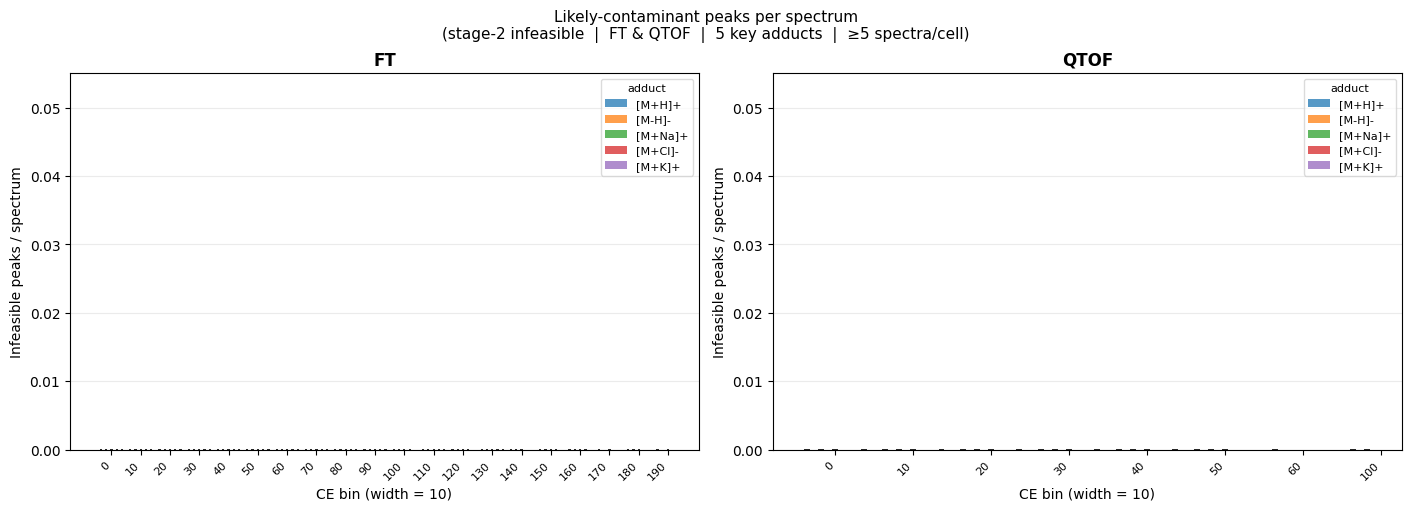

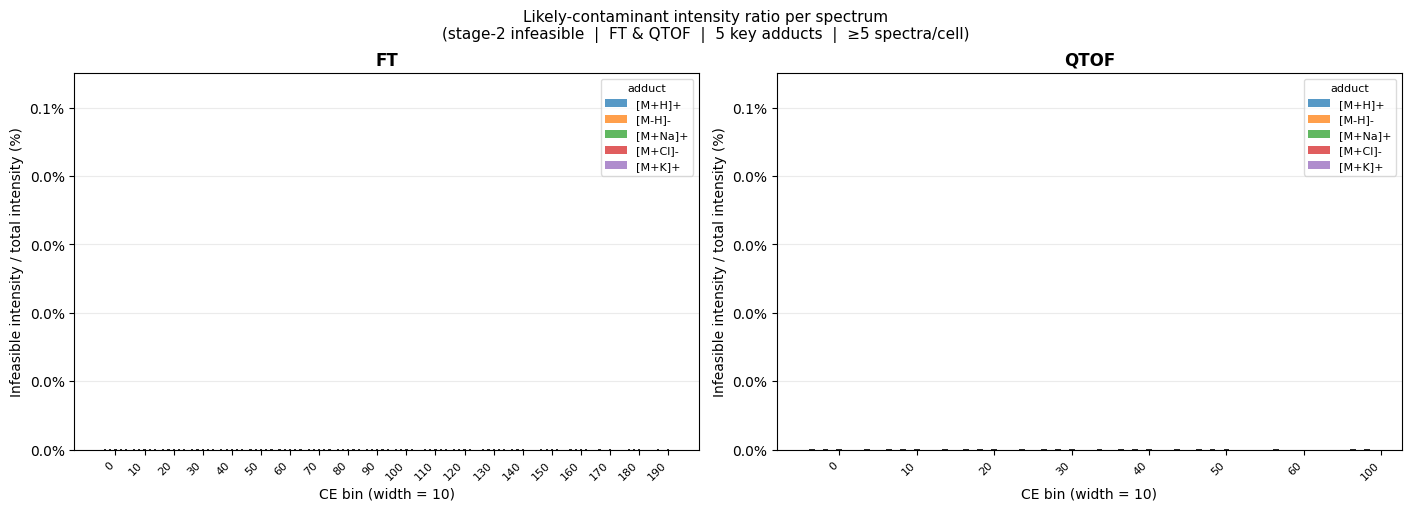

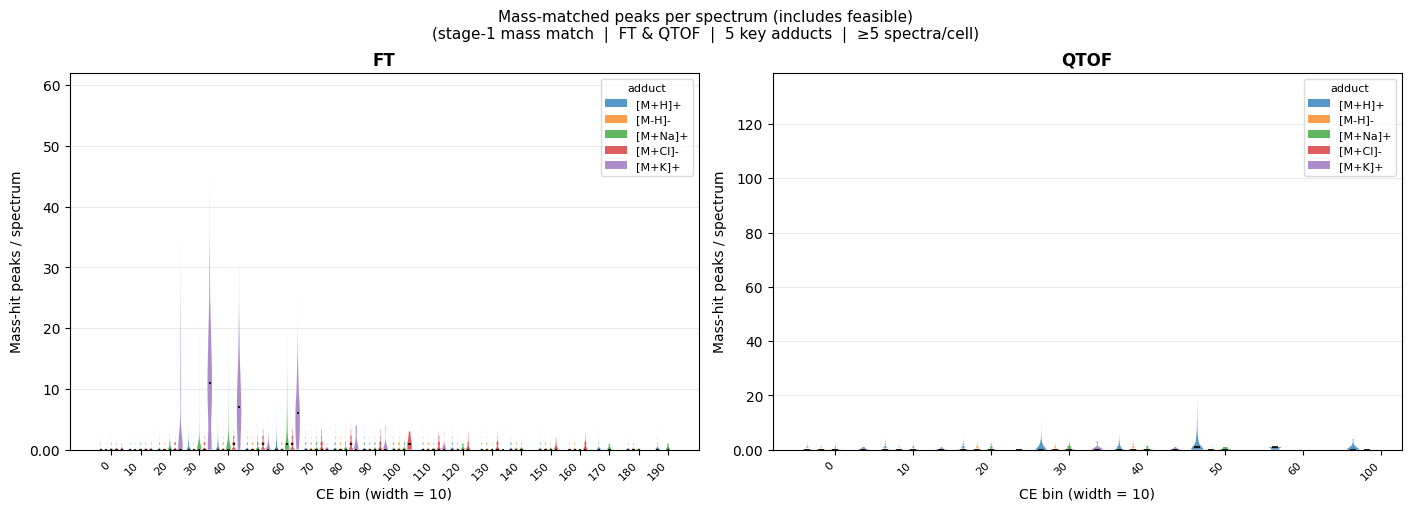

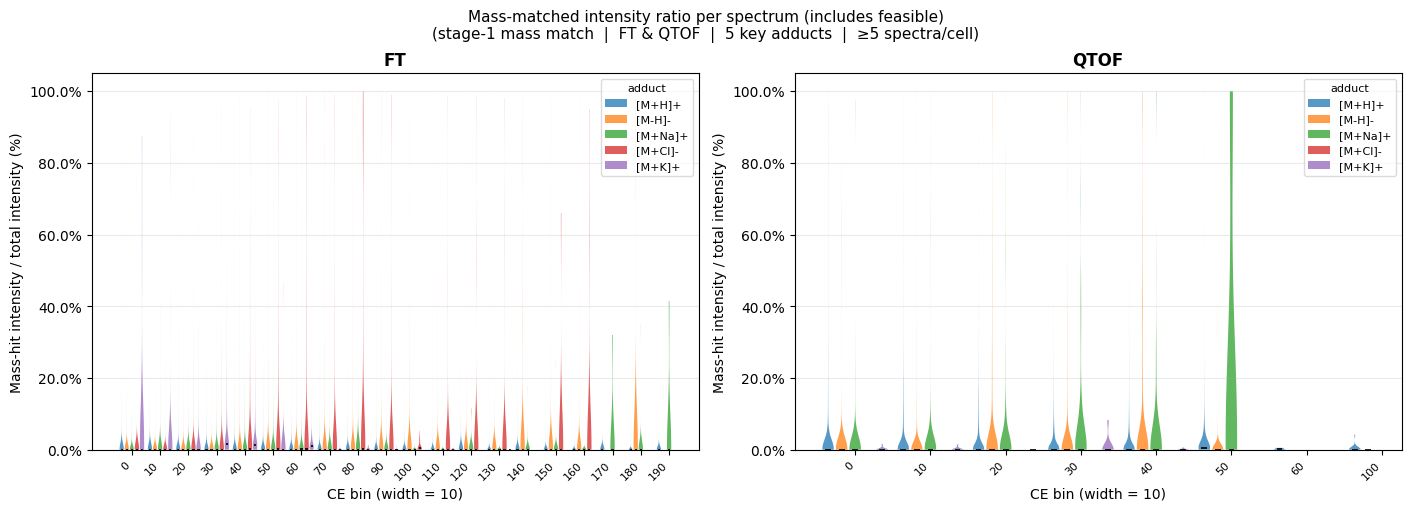

In [24]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# ── Focus: FT and QTOF only, 5 key adducts ────────────────────────────────
FOCUS_INSTS   = ["FT", "QTOF"]
FOCUS_ADDUCTS = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+Cl]-", "[M+K]+"]

plot_df = spec_stats_ext[
    spec_stats_ext["ce_bin"].notna()
    & spec_stats_ext["inst_type"].isin(FOCUS_INSTS)
    & spec_stats_ext["prec_type"].isin(FOCUS_ADDUCTS)
].copy()
plot_df["ce_bin"] = plot_df["ce_bin"].astype(int)

MIN_N = 5
cell_counts = (
    plot_df.groupby(["inst_type", "prec_type", "ce_bin"], observed=True)["spec_id"]
    .count()
    .reset_index(name="n")
)
valid_cells = cell_counts[cell_counts["n"] >= MIN_N][["inst_type", "prec_type", "ce_bin"]]
plot_df = plot_df.merge(valid_cells, on=["inst_type", "prec_type", "ce_bin"], how="inner")

inst_order  = [i for i in FOCUS_INSTS  if i in plot_df["inst_type"].unique()]
palette     = {a: plt.cm.tab10.colors[i % 10] for i, a in enumerate(FOCUS_ADDUCTS)}

NROWS, NCOLS = 1, 2


# ── helper ────────────────────────────────────────────────────────────────
def _plot_grid(metric_col: str, ylabel: str, title: str, stage_label: str, pct: bool = False):
    fig, axes = plt.subplots(
        NROWS, NCOLS,
        figsize=(7 * NCOLS, 5 * NROWS),
        sharey=False,
        constrained_layout=True,
    )
    axes_flat = axes.flatten()

    for ax, inst in zip(axes_flat, inst_order):
        sub = plot_df[plot_df["inst_type"] == inst]
        ce_bins    = sorted(sub["ce_bin"].unique())
        n_bins     = len(ce_bins)
        n_adducts  = len(FOCUS_ADDUCTS)
        slot_width = 0.9 / max(n_adducts, 1)
        offsets    = np.arange(n_adducts) * slot_width - (n_adducts - 1) * slot_width / 2

        legend_handles = []
        for i, adduct in enumerate(FOCUS_ADDUCTS):
            color = palette[adduct]
            grp = sub[sub["prec_type"] == adduct]
            for j, cb in enumerate(ce_bins):
                vals = grp.loc[grp["ce_bin"] == cb, metric_col].dropna().values
                if len(vals) < MIN_N:
                    continue
                vals = np.clip(vals, 0, None)
                x_center = j + offsets[i]
                vp = ax.violinplot(
                    vals,
                    positions=[x_center],
                    widths=slot_width * 0.85,
                    showmedians=True,
                    showextrema=False,
                )
                for body in vp["bodies"]:
                    body.set_facecolor(color)
                    body.set_alpha(0.75)
                    body.set_edgecolor("none")
                vp["cmedians"].set_color("black")
                vp["cmedians"].set_linewidth(1.2)

            legend_handles.append(
                plt.Rectangle((0, 0), 1, 1, fc=color, alpha=0.75, label=adduct)
            )

        ax.set_title(inst, fontweight="bold")
        ax.set_xlabel("CE bin (width = 10)")
        ax.set_ylabel(ylabel)
        ax.set_xticks(range(n_bins))
        ax.set_xticklabels(ce_bins, rotation=45, ha="right", fontsize=8)
        ax.set_ylim(bottom=0)
        if pct:
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.1f}%"))
        else:
            ax.yaxis.set_major_formatter(mticker.FuncFormatter(
                lambda x, _: f"{x:,.0f}" if x >= 1 else f"{x:.2f}"
            ))
        ax.grid(axis="y", alpha=0.25)
        ax.legend(handles=legend_handles, title="adduct", fontsize=8,
                  title_fontsize=8, loc="upper right", framealpha=0.7)

    fig.suptitle(
        f"{title}\n({stage_label}  |  FT & QTOF  |  5 key adducts  |  ≥{MIN_N} spectra/cell)",
        fontsize=11,
    )
    plt.show()


# ── Plot 1: infeasible (stage-2) peaks per spectrum ───────────────────────
_plot_grid(
    "infeas_hit_peaks",
    "Infeasible peaks / spectrum",
    "Likely-contaminant peaks per spectrum",
    "stage-2 infeasible",
)

# ── Plot 2: infeasible (stage-2) intensity ratio per spectrum ─────────────
_plot_grid(
    "infeas_pct_int",
    "Infeasible intensity / total intensity (%)",
    "Likely-contaminant intensity ratio per spectrum",
    "stage-2 infeasible",
    pct=True,
)

# ── Plot 3: mass-matched (stage-1) peaks per spectrum ─────────────────────
_plot_grid(
    "mass_hit_peaks",
    "Mass-hit peaks / spectrum",
    "Mass-matched peaks per spectrum (includes feasible)",
    "stage-1 mass match",
)

# ── Plot 4: mass-matched (stage-1) intensity ratio per spectrum ───────────
_plot_grid(
    "mass_hit_pct_int",
    "Mass-hit intensity / total intensity (%)",
    "Mass-matched intensity ratio per spectrum (includes feasible)",
    "stage-1 mass match",
    pct=True,
)

## 11. FT/QTOF × key-adduct summary statistics

In [25]:
# §8-style aggregate table for FT & QTOF × 5 key adducts.
# *_pct_int: mean of per-spectrum (noise_int / total_int) ratios,
#   i.e. each spectrum is normalised to 1.0 before averaging.
sub = spec_stats_ext[
    spec_stats_ext["inst_type"].isin(FOCUS_INSTS)
    & spec_stats_ext["prec_type"].isin(FOCUS_ADDUCTS)
].copy()

adduct_totals = (
    sub
    .groupby(["inst_type", "prec_type"], observed=True)
    .agg(
        n_spectra        =("spec_id",            "count"),
        total_peaks      =("total_peaks",         "sum"),
        total_intensity  =("total_intensity",     "sum"),
        mass_hit_peaks   =("mass_hit_peaks",      "sum"),
        mass_hit_int     =("mass_hit_int",        "sum"),
        infeas_peaks     =("infeas_hit_peaks",    "sum"),
        infeas_int       =("infeas_hit_int",      "sum"),
        # per-spectrum normalised intensity ratio (mean across spectra)
        mass_hit_pct_int =("mass_hit_pct_int",    "mean"),
        infeas_pct_int   =("infeas_pct_int",      "mean"),
    )
    .reset_index()
)

adduct_totals["mass_hit_pct_peaks"] = 100 * adduct_totals["mass_hit_peaks"] / adduct_totals["total_peaks"]
adduct_totals["infeas_pct_peaks"]   = 100 * adduct_totals["infeas_peaks"]   / adduct_totals["total_peaks"]

# Sort by inst_type then by FOCUS_ADDUCTS order
adduct_totals["_adduct_order"] = adduct_totals["prec_type"].map(
    {a: i for i, a in enumerate(FOCUS_ADDUCTS)}
)
adduct_totals = adduct_totals.sort_values(["inst_type", "_adduct_order"]).drop(columns="_adduct_order")

display_cols = [
    "inst_type", "prec_type", "n_spectra",
    "total_peaks",     "total_intensity",
    "mass_hit_peaks",  "mass_hit_pct_peaks",
    "mass_hit_int",    "mass_hit_pct_int",
    "infeas_peaks",    "infeas_pct_peaks",
    "infeas_int",      "infeas_pct_int",
]
fmt = {
    "n_spectra":          "{:,.0f}",
    "total_peaks":        "{:,.0f}",
    "total_intensity":    "{:,.0f}",
    "mass_hit_peaks":     "{:,.0f}",
    "mass_hit_pct_peaks": "{:.2f}%",
    "mass_hit_int":       "{:,.0f}",
    "mass_hit_pct_int":   "{:.2f}%",
    "infeas_peaks":       "{:,.0f}",
    "infeas_pct_peaks":   "{:.2f}%",
    "infeas_int":         "{:,.0f}",
    "infeas_pct_int":     "{:.2f}%",
}

print("Noise estimates — FT & QTOF × 5 key adducts")
print("(mass_hit_pct_int / infeas_pct_int = mean of per-spectrum intensity fractions)")
print("=" * 80)
display(adduct_totals[display_cols].style.format(fmt))

Noise estimates — FT & QTOF × 5 key adducts
(mass_hit_pct_int / infeas_pct_int = mean of per-spectrum intensity fractions)


## 12. Contamination-rate heatmap — % spectra with infeasible hit, by adduct × CE bin

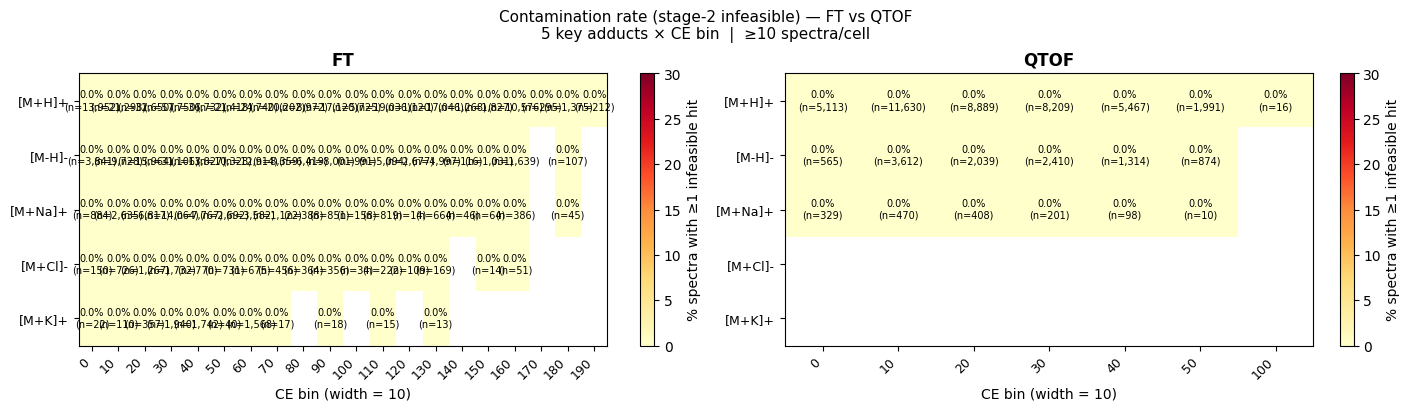

ValueError: zero-size array to reduction operation fmax which has no identity

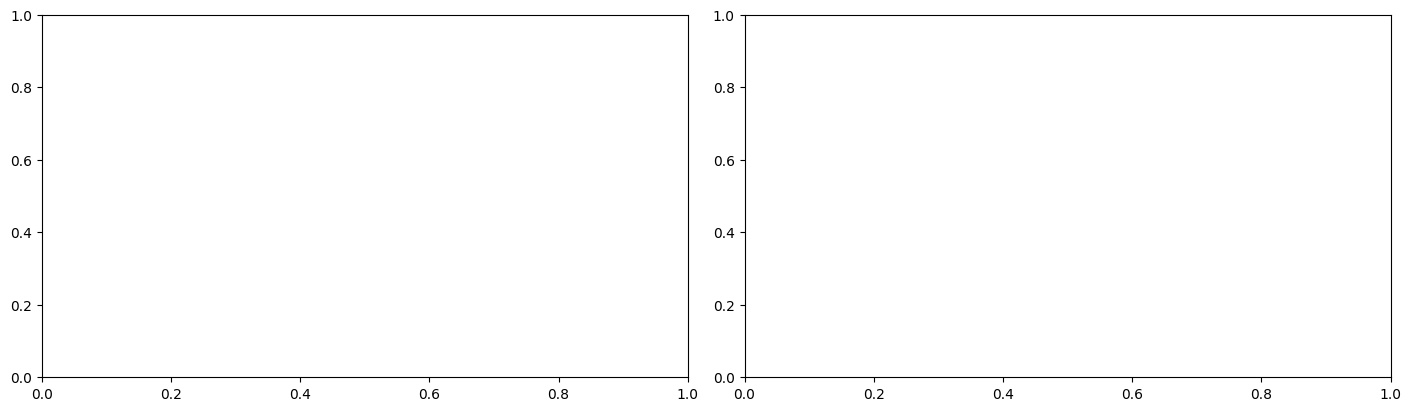

In [26]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

# Build (inst_type, prec_type, ce_bin) → pct_infeas for CE-binned subset
hm_df = spec_stats_ext[
    spec_stats_ext["ce_bin"].notna()
    & spec_stats_ext["inst_type"].isin(FOCUS_INSTS)
    & spec_stats_ext["prec_type"].isin(FOCUS_ADDUCTS)
].copy()
hm_df["ce_bin"] = hm_df["ce_bin"].astype(int)

MIN_HM = 10  # minimum spectra per cell to show a value

hm_grp = (
    hm_df
    .groupby(["inst_type", "prec_type", "ce_bin"], observed=True)
    .agg(
        n          =("spec_id",          "count"),
        n_infeas   =("infeas_hit_peaks", lambda x: (x > 0).sum()),
        med_infeas =("infeas_pct_int",   "median"),
    )
    .reset_index()
)
hm_grp = hm_grp[hm_grp["n"] >= MIN_HM].copy()
hm_grp["pct_infeas"] = 100 * hm_grp["n_infeas"] / hm_grp["n"]

ce_bins_all = sorted(hm_grp["ce_bin"].unique())

fig, axes = plt.subplots(1, 2, figsize=(7 * 2, 4), constrained_layout=True)

for ax, inst in zip(axes, FOCUS_INSTS):
    sub = hm_grp[hm_grp["inst_type"] == inst]
    ce_bins = sorted(sub["ce_bin"].unique())

    # Build matrix: rows = adducts, cols = CE bins
    mat       = np.full((len(FOCUS_ADDUCTS), len(ce_bins)), np.nan)
    annot     = np.full((len(FOCUS_ADDUCTS), len(ce_bins)), "", dtype=object)
    cb_idx    = {cb: j for j, cb in enumerate(ce_bins)}

    for _, row in sub.iterrows():
        i = FOCUS_ADDUCTS.index(row["prec_type"])
        j = cb_idx[row["ce_bin"]]
        mat[i, j]   = row["pct_infeas"]
        annot[i, j] = f"{row['pct_infeas']:.1f}%\n(n={int(row['n']):,})"

    im = ax.imshow(mat, aspect="auto", cmap="YlOrRd", vmin=0, vmax=max(30, np.nanmax(mat)))
    ax.set_xticks(range(len(ce_bins)))
    ax.set_xticklabels(ce_bins, rotation=45, ha="right", fontsize=9)
    ax.set_yticks(range(len(FOCUS_ADDUCTS)))
    ax.set_yticklabels(FOCUS_ADDUCTS, fontsize=9)
    ax.set_xlabel("CE bin (width = 10)")
    ax.set_title(inst, fontweight="bold")

    for i in range(len(FOCUS_ADDUCTS)):
        for j in range(len(ce_bins)):
            if annot[i, j]:
                ax.text(j, i, annot[i, j], ha="center", va="center",
                        fontsize=7, color="black" if mat[i, j] < 20 else "white")

    plt.colorbar(im, ax=ax, label="% spectra with ≥1 infeasible hit", fraction=0.046)

fig.suptitle(
    f"Contamination rate (stage-2 infeasible) — FT vs QTOF\n"
    f"5 key adducts × CE bin  |  ≥{MIN_HM} spectra/cell",
    fontsize=11,
)
plt.show()

# ── Extra: median infeasible intensity % heatmap (among affected spectra) ──
fig2, axes2 = plt.subplots(1, 2, figsize=(7 * 2, 4), constrained_layout=True)

hm_grp2 = (
    hm_df[hm_df["infeas_hit_peaks"] > 0]
    .groupby(["inst_type", "prec_type", "ce_bin"], observed=True)
    .agg(
        n          =("spec_id",       "count"),
        med_int    =("infeas_pct_int", "median"),
        p75_int    =("infeas_pct_int", lambda x: x.quantile(0.75)),
    )
    .reset_index()
)
hm_grp2 = hm_grp2[hm_grp2["n"] >= MIN_HM].copy()

for ax2, inst in zip(axes2, FOCUS_INSTS):
    sub2 = hm_grp2[hm_grp2["inst_type"] == inst]
    ce_bins2 = sorted(sub2["ce_bin"].unique())
    mat2     = np.full((len(FOCUS_ADDUCTS), len(ce_bins2)), np.nan)
    annot2   = np.full((len(FOCUS_ADDUCTS), len(ce_bins2)), "", dtype=object)
    cb_idx2  = {cb: j for j, cb in enumerate(ce_bins2)}

    for _, row in sub2.iterrows():
        i = FOCUS_ADDUCTS.index(row["prec_type"])
        j = cb_idx2[row["ce_bin"]]
        mat2[i, j]   = row["med_int"]
        annot2[i, j] = f"{row['med_int']:.1f}%"

    im2 = ax2.imshow(mat2, aspect="auto", cmap="Blues", vmin=0, vmax=max(20, np.nanmax(mat2)))
    ax2.set_xticks(range(len(ce_bins2)))
    ax2.set_xticklabels(ce_bins2, rotation=45, ha="right", fontsize=9)
    ax2.set_yticks(range(len(FOCUS_ADDUCTS)))
    ax2.set_yticklabels(FOCUS_ADDUCTS, fontsize=9)
    ax2.set_xlabel("CE bin (width = 10)")
    ax2.set_title(inst, fontweight="bold")

    for i in range(len(FOCUS_ADDUCTS)):
        for j in range(len(ce_bins2)):
            if annot2[i, j]:
                ax2.text(j, i, annot2[i, j], ha="center", va="center",
                         fontsize=8, color="black" if mat2[i, j] < 12 else "white")

    plt.colorbar(im2, ax=ax2, label="Median infeasible intensity % (affected spectra)",
                 fraction=0.046)

fig2.suptitle(
    f"Median contaminant intensity fraction (stage-2, affected spectra only) — FT vs QTOF\n"
    f"5 key adducts × CE bin  |  ≥{MIN_HM} affected spectra/cell",
    fontsize=11,
)
plt.show()

## 13. Contamination distribution: few spectra heavily contaminated vs. many lightly contaminated?

In [ ]:
# ── Bucket spectra by infeasible intensity fraction ────────────────────────
LABELS = ["0%", "0–1%", "1–5%", "5–20%", "20–50%", ">50%"]

ii = spec_stats["infeas_pct_int"]  # pandas Series — used for all boolean masks
pct_int = ii.values                 # numpy array — used for fast bucket counts

bucket_counts = np.array([
    (pct_int == 0).sum(),
    ((pct_int > 0) & (pct_int < 1)).sum(),
    ((pct_int >= 1) & (pct_int < 5)).sum(),
    ((pct_int >= 5) & (pct_int < 20)).sum(),
    ((pct_int >= 20) & (pct_int < 50)).sum(),
    (pct_int >= 50).sum(),
], dtype=np.int64)

bucket_pct = 100 * bucket_counts / len(pct_int)

print("Contamination level distribution (infeasible intensity % per spectrum):")
for label, count, pct in zip(LABELS, bucket_counts, bucket_pct):
    print(f"  {label:>8s}: {count:>9,} spectra  ({pct:.2f}%)")

# ── Plot 1: bar chart of bucket counts ────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)

ax = axes[0]
bars = ax.bar(LABELS, bucket_counts, color=plt.cm.YlOrRd(np.linspace(0.1, 0.9, len(LABELS))))
ax.set_xlabel("Infeasible intensity fraction")
ax.set_ylabel("Number of spectra")
ax.set_title("All spectra (incl. 0%)", fontweight="bold")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e6:.1f}M"))
for bar, count, pct in zip(bars, bucket_counts, bucket_pct):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
            f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)
ax.grid(axis="y", alpha=0.3)

# ── Plot 2: zoom into affected spectra only ────────────────────────────────
ax2 = axes[1]
nonzero_counts = bucket_counts[1:]
nonzero_labels = LABELS[1:]
nonzero_pct = 100 * nonzero_counts / nonzero_counts.sum()
bars2 = ax2.bar(nonzero_labels, nonzero_counts,
                color=plt.cm.YlOrRd(np.linspace(0.2, 0.9, len(nonzero_labels))))
ax2.set_xlabel("Infeasible intensity fraction")
ax2.set_ylabel("Number of spectra")
ax2.set_title("Affected spectra only (infeas > 0)", fontweight="bold")
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
for bar, count, pct in zip(bars2, nonzero_counts, nonzero_pct):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
             f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)
ax2.grid(axis="y", alpha=0.3)

# ── Plot 3: CDF among affected spectra, by instrument type ────────────────
ax3 = axes[2]
affected = spec_stats[spec_stats["infeas_pct_int"] > 0].copy()
inst_palette = {"FT": "steelblue", "QTOF": "darkorange", "IT": "green",
                "QQQ": "purple", "Other": "gray"}
x_vals = np.linspace(0, 100, 1000)
for inst, color in inst_palette.items():
    sub = affected[affected["inst_type"] == inst]["infeas_pct_int"].values
    if len(sub) < 10:
        continue
    cdf = np.searchsorted(np.sort(sub), x_vals) / len(sub)
    ax3.plot(x_vals, 100 * cdf, label=f"{inst} (n={len(sub):,})", color=color, linewidth=1.8)

ax3.axvline(5,  color="red",   linestyle="--", linewidth=0.8, alpha=0.6, label="5% threshold")
ax3.axvline(20, color="black", linestyle="--", linewidth=0.8, alpha=0.6, label="20% threshold")
ax3.set_xlabel("Infeasible intensity fraction (%)")
ax3.set_ylabel("Cumulative % of affected spectra")
ax3.set_title("CDF — affected spectra by instrument", fontweight="bold")
ax3.legend(fontsize=8, loc="lower right")
ax3.grid(alpha=0.3)
ax3.set_xlim(0, 100)
ax3.set_ylim(0, 100)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:.0f}%"))

fig.suptitle(
    "Is contamination concentrated in a few spectra or spread across many?
"
    "(stage-2 infeasible intensity fraction per spectrum)",
    fontsize=12,
)
plt.show()

# ── Intensity share by contamination bucket ────────────────────────────────
print("
Intensity share by contamination bucket (among all infeasible intensity):")
total_infeas_int_sum = spec_stats["infeas_hit_int"].sum()
bucket_int = np.array([
    spec_stats.loc[ii == 0,                    "infeas_hit_int"].sum(),
    spec_stats.loc[(ii > 0) & (ii < 1),        "infeas_hit_int"].sum(),
    spec_stats.loc[(ii >= 1) & (ii < 5),       "infeas_hit_int"].sum(),
    spec_stats.loc[(ii >= 5) & (ii < 20),      "infeas_hit_int"].sum(),
    spec_stats.loc[(ii >= 20) & (ii < 50),     "infeas_hit_int"].sum(),
    spec_stats.loc[ii >= 50,                   "infeas_hit_int"].sum(),
])
for label, count, spec_pct, int_val in zip(LABELS, bucket_counts, bucket_pct, bucket_int):
    int_pct = 100 * int_val / total_infeas_int_sum if total_infeas_int_sum > 0 else 0
    print(f"  {label:>8s}: {count:>9,} spectra ({spec_pct:.1f}%)  ->  {int_pct:.1f}% of total contam. intensity")
